# Toronto West PM2.5 forecasting

A reproducible historical benchmark using quality-assured **NAPS hourly PM2.5**
and **ECCC hourly weather observations**, covering 2020–2024.

The target is daily mean PM2.5 in **µg/m³**, not the original derived AQI.
The forecast represents one monitoring location, not all of Toronto.
See [data provenance](docs/data.md) and [evaluation design](docs/evaluation.md).

Install `requirements-notebook.txt`, launch Jupyter from the repository root, then
**Restart Kernel and Run All**. The committed prepared snapshot allows an offline run.
Downloading refreshed raw data is a separate, explicit step: `python data_sources.py --refresh`.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
from IPython.display import display, Image

import sys
ROOT = Path.cwd()
if not (ROOT / "forecast.py").exists() and (ROOT.parent / "forecast.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from forecast import load_data, run
INPUT = ROOT / "data/processed/daily_pm25.csv"
manifest = json.loads(INPUT.with_suffix(".manifest.json").read_text())
assert hashlib.sha256(INPUT.read_bytes()).hexdigest() == manifest["prepared_sha256"]
frame = load_data(INPUT)
print(f"{len(frame):,} calendar days; {frame.PM25.notna().sum():,} observed targets")
print("Pollution station:", manifest["naps_station"]["Station_Name"])
print("Weather station:", manifest["weather_station"]["properties"]["STATION_NAME"])
display(pd.DataFrame(manifest["annual_quality"]))

1,827 calendar days; 1,801 observed targets
Pollution station: TORONTO WEST - 125 RESOURCES. RD.
Weather station: TORONTO INTL A


,methods,latitude,longitude,rejected_negative_hours_excluding_sentinel,valid_days,days,year
0,[184],43.70944,-79.5435,0,358,366,2020
1,[184],43.70944,-79.5435,0,360,365,2021
2,"[184, 636]",43.70944,-79.5435,0,360,365,2022
3,[636],43.70944,-79.5435,0,359,365,2023
4,[636],43.70944,-79.5435,0,364,366,2024


## Quality and missingness

Days need at least 18 valid hourly pollutant observations. Missing days remain in
the calendar and are never filled as labels. Zeros are valid. Weather means also
require 18 unflagged hourly readings, independently for each variable.

Source files retain instrument method identifiers. Complementary methods in 2022
are combined by hour; overlapping valid readings fail validation. Method changes
remain a comparability limitation even though the site is unchanged.

Days failing the target coverage requirement: 26


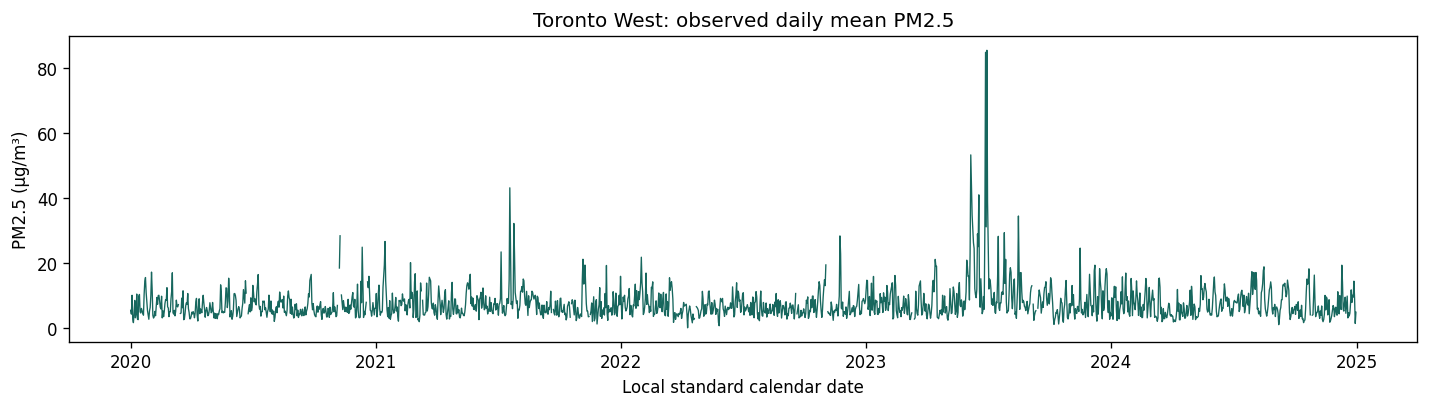

,missing_days
PM25,26
valid_hours,0
naps_station_id,0
temperature_c,1
temperature_c_hours,0
humidity_pct,1
humidity_pct_hours,0
wind_speed_kmh,1
wind_speed_kmh_hours,0
pressure_kpa,1


In [2]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(frame.index, frame.PM25, color="#17675e", linewidth=0.8)
ax.set(title="Toronto West: observed daily mean PM2.5", ylabel="PM2.5 (µg/m³)", xlabel="Local standard calendar date")
fig.tight_layout()
plt.show()
print("Days failing the target coverage requirement:", frame.PM25.isna().sum())
display(frame.isna().sum().rename("missing_days").to_frame())

## Chronological benchmarks

Models are fixed before each evaluation year: train 2020–2022 → evaluate 2023;
train 2020–2023 → evaluate 2024. Separate direct models predict horizons 1–7.
No target-day observed weather is used. Pollution and weather features describe
the completed origin day and earlier history.

Ridge and Random Forest use fixed settings. A pollution-only forest tests whether
weather helps. Persistence and weekly seasonal naïve use the same eligible
origin/target pairs. Missing weather predictors are imputed using training-only
medians; missing targets are excluded. These are retrospective, overlapping
forecasts, not independent experiments or live operational performance.

In [3]:
tables = []
for year, days in [(2023, 365), (2024, 366)]:
    metrics = run(INPUT, ROOT / f"reports/{year}", test_days=days,
                  horizon=7, trees=200, end_date=f"{year}-12-31")
    tables.append(metrics.assign(evaluation_year=year))
comparison = pd.concat(tables, ignore_index=True)
display(comparison.loc[comparison.horizon.isin([1, 7])].round(3))

,model,horizon,n_forecasts,MAE,RMSE,MAE_skill_vs_persistence,evaluation_year
0,ridge_weather,1,335,3.935,7.623,0.143,2023
1,forest_lags,1,335,4.247,8.076,0.075,2023
2,forest_weather,1,335,4.065,8.076,0.114,2023
3,persistence,1,335,4.590,8.189,0.000,2023
4,seasonal_naive,1,335,6.925,12.141,-0.509,2023
30,ridge_weather,7,326,4.921,9.357,0.298,2023
31,forest_lags,7,326,4.825,9.155,0.312,2023
32,forest_weather,7,326,4.859,9.138,0.307,2023
33,persistence,7,326,7.008,12.278,0.000,2023
34,seasonal_naive,7,326,7.008,12.278,0.000,2023


2023: one-day predictions and error by horizon
2024: one-day predictions and error by horizon


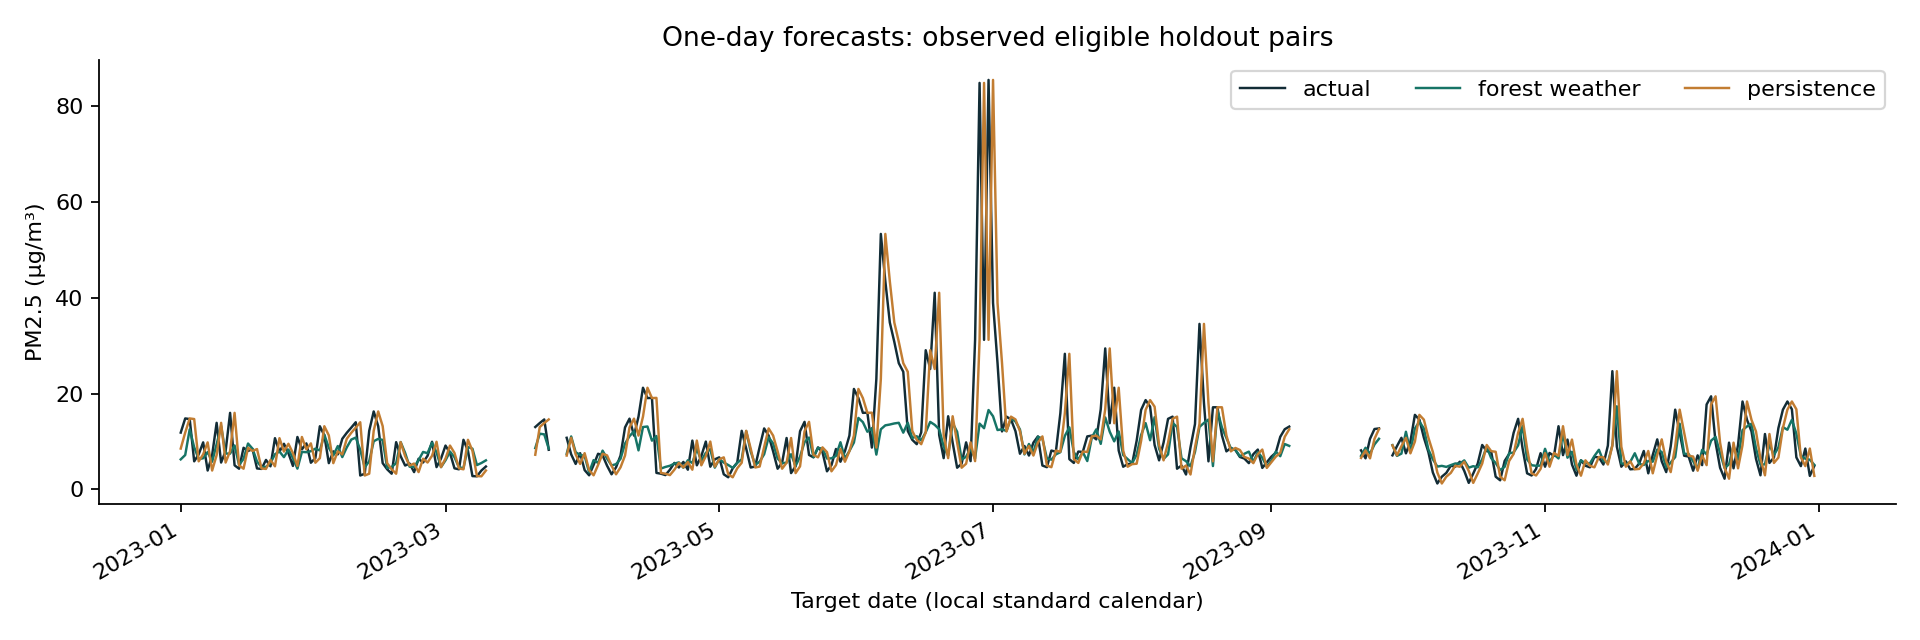

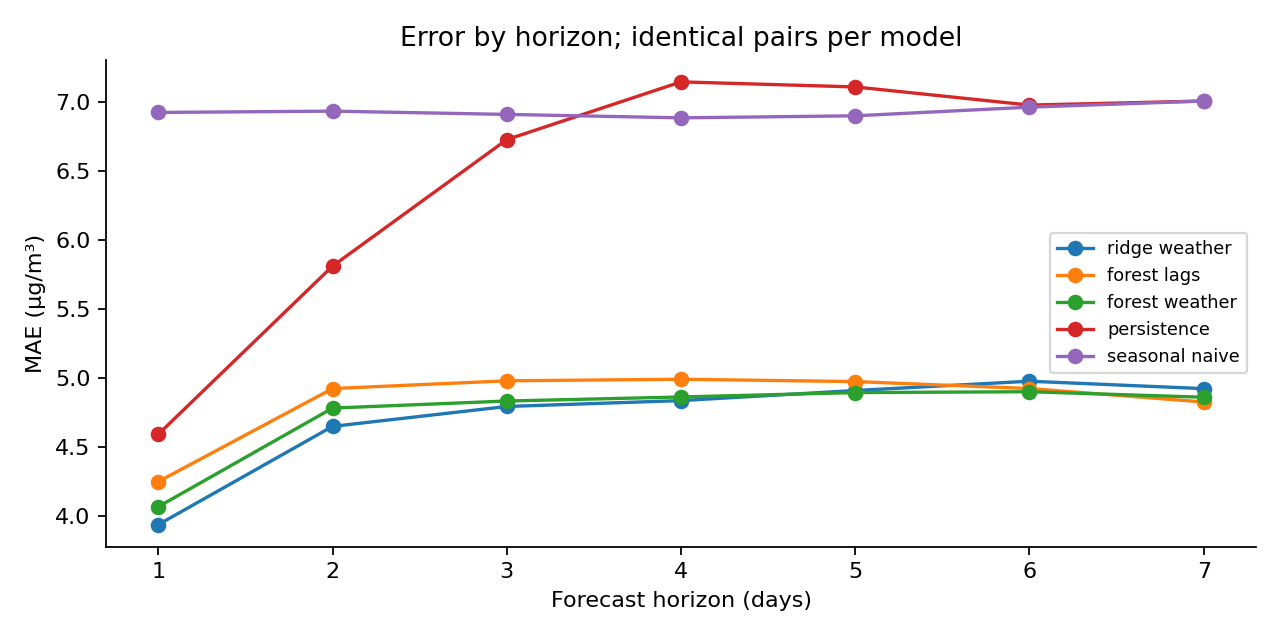

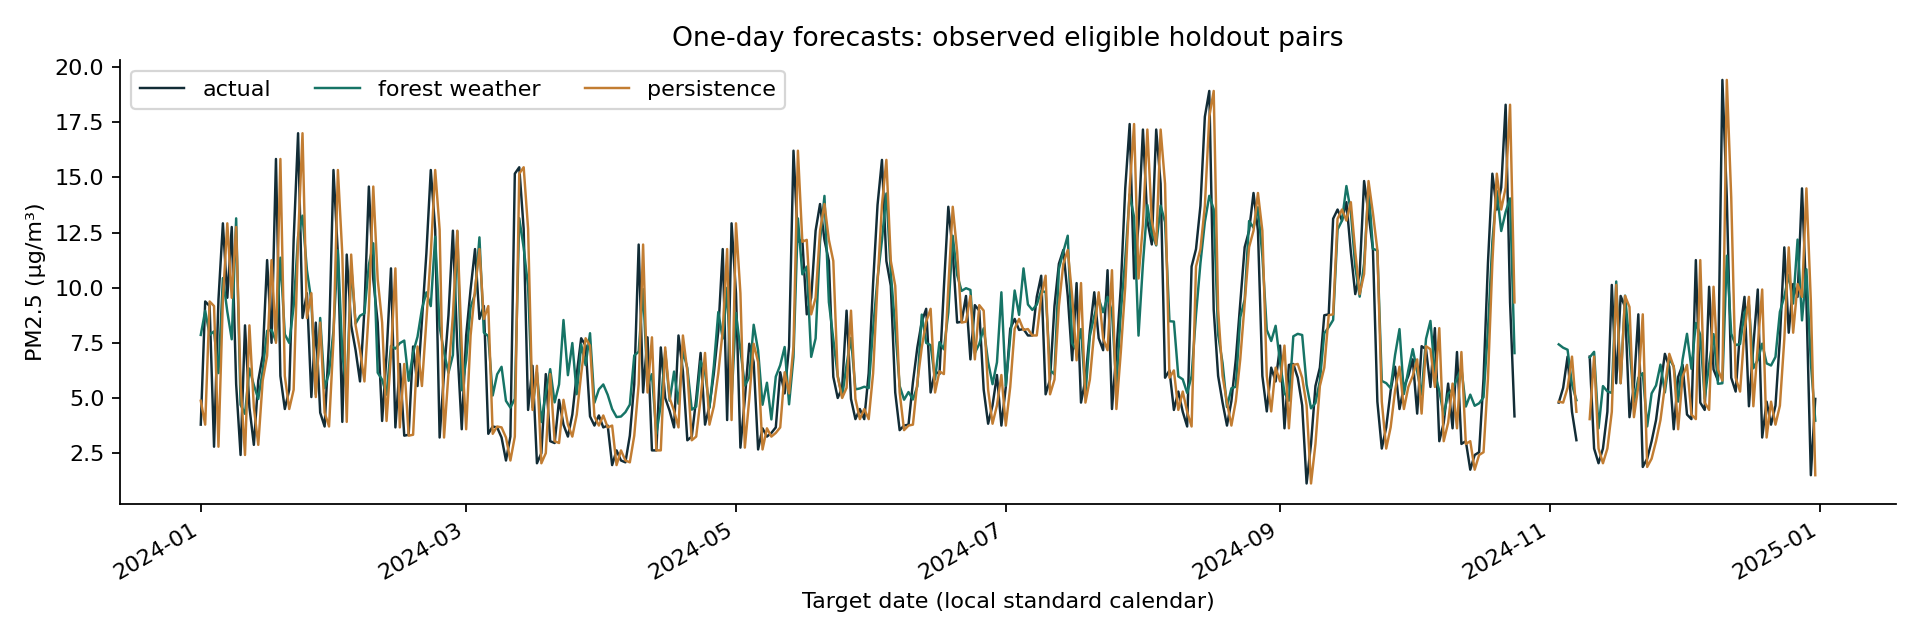

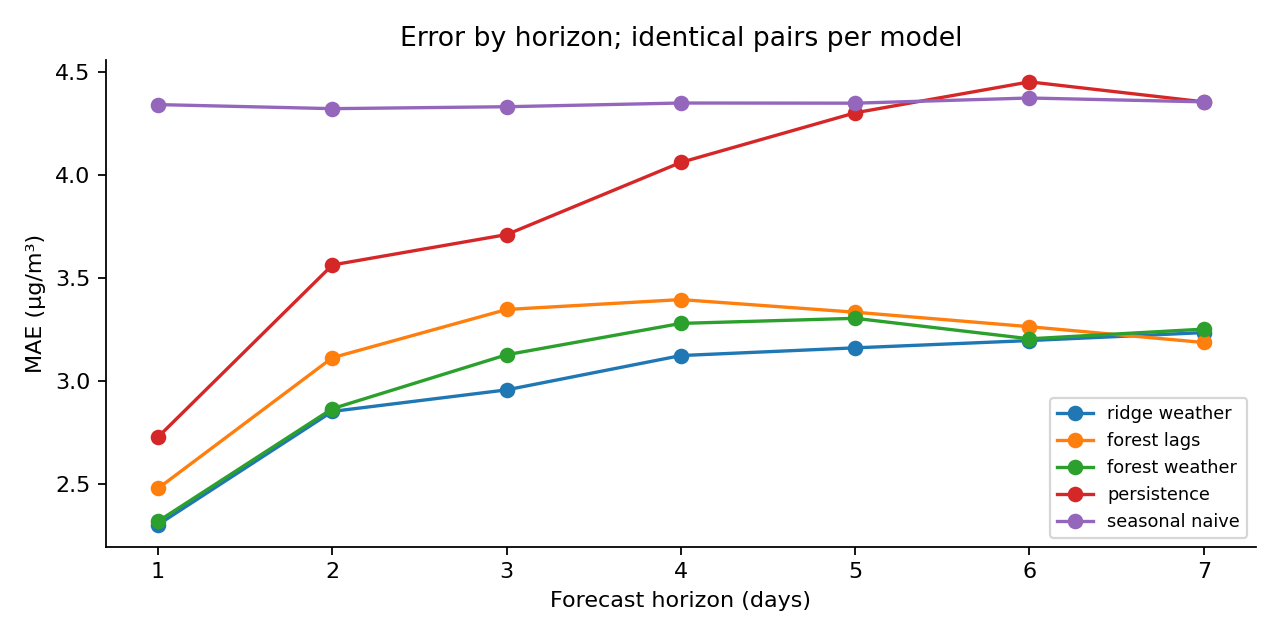

In [4]:
for year in [2023, 2024]:
    print(f"{year}: one-day predictions and error by horizon")
    display(Image(filename=str(ROOT / f"reports/{year}/backtest.png")))
    display(Image(filename=str(ROOT / f"reports/{year}/horizon_errors.png")))

## Interpretation and limitations

- Compare results by horizon and year; do not call one model universally best.
- The 2023 evaluation has larger errors than 2024. These data alone do not establish
  which events caused individual errors.
- Weather-assisted forests should be compared with pollution-only forests; more
  features need not improve every horizon.
- Scores are conditional on available observed pollution history. Excluded gaps
  are reported, and difficult missing periods may affect representativeness.
- Finalized observations are assumed available after each completed origin day.
  Archive revisions and real publication delays are not simulated.
- No calibrated uncertainty interval, official AQHI, or public-health guidance is produced.
- Forecasts beyond the 2024 archive end are historical projections, not forecasts
  for today's air quality.

Full metrics, prediction rows, monthly errors, and run settings are saved under
`reports/2023/` and `reports/2024/`. The original notebook is retained under
`notebooks/legacy/` and is not used by this pipeline.

In [5]:
metadata = json.loads((ROOT / "reports/2024/run.json").read_text())
display(pd.DataFrame({"horizon": list(metadata["eligible_pairs_by_horizon"]),
                      "eligible_pairs": list(metadata["eligible_pairs_by_horizon"].values())}))
print(metadata["forecast_status"])
display(pd.read_csv(ROOT / "reports/2024/forecast.csv"))

Archive-end projection; not a current forecast


,horizon,eligible_pairs
0,1,355
1,2,353
2,3,352
3,4,351
4,5,350
5,6,349
6,7,348


,origin,Date,horizon,ridge_weather,forest_lags,forest_weather,persistence,seasonal_naive
0,2024-12-31,2025-01-01,1,4.590659,6.672260,6.922279,4.958333,7.958333
1,2024-12-31,2025-01-02,2,4.333867,8.248518,6.531254,4.958333,10.166667
2,2024-12-31,2025-01-03,3,5.218372,8.522015,6.926245,4.958333,9.583333
3,2024-12-31,2025-01-04,4,6.046380,7.924301,7.313121,4.958333,14.500000
4,2024-12-31,2025-01-05,5,7.014568,7.656242,8.442571,4.958333,9.375000
5,2024-12-31,2025-01-06,6,7.072263,8.968907,8.628587,4.958333,1.500000
6,2024-12-31,2025-01-07,7,7.815087,9.199299,9.360594,4.958333,4.958333
